# PHẦN 2. KHAI PHÁ VÀ PHÂN TÍCH DỮ LIỆU (EDA)
**Đề tài:** Phân tích cảm xúc bình luận phim – bộ dữ liệu IMDB Dataset.csv

**Cách dùng:** đặt file `IMDB_Dataset.csv` cùng thư mục với notebook (hoặc tải lên Google Colab), rồi chạy lần lượt các ô từ trên xuống.
Thư viện cần có: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`. WordCloud là tùy chọn (`pip install wordcloud`).

**Nguyên tắc chống rò rỉ dữ liệu:** các mục 2.1–2.4 chỉ mô tả toàn bộ dữ liệu. Từ mục 2.5 trở đi (từ vựng, n-gram, từ phân biệt) chỉ dùng **tập train** (80%).

*Các phần "Nhận xét" bên dưới dùng số liệu thật khi chạy trên file IMDB Dataset.csv. Nếu bạn đổi tham số (ví dụ `random_state`, `min_df`) thì số liệu có thể thay đổi nhẹ, hãy cập nhật lại.*

In [ ]:

!pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2.0. Nạp dữ liệu và khai báo thư viện

In [ ]:
import re
import warnings
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
DATA_PATH = "IMDB Dataset.csv"

# Đọc file CSV chuẩn bằng engine python và skip bad lines để xử lý triệt để lỗi định dạng nháy kép
try:
    df = pd.read_csv(DATA_PATH, engine="python", on_bad_lines="skip")
except Exception:
    df = pd.read_csv(DATA_PATH, quoting=csv.QUOTE_MINIMAL, on_bad_lines="skip")

print("Kích thước dữ liệu gốc:", df.shape)
print("\nThông tin dữ liệu:")
print(df.info())
print("\nSố lượng giá trị thiếu (Null):")
print(df.isnull().sum())
print("\n5 dòng đầu tiên:")
print(df.head())

Kích thước dữ liệu gốc: (50000, 2)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB
None

Số lượng giá trị thiếu (Null):
review       0
sentiment    0
dtype: int64

5 dòng đầu tiên:
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


## 2.1. Tổng quan dữ liệu

In [ ]:
n_duplicates = df.duplicated(subset=["review"]).sum()
print(f"\nSố bình luận trùng lặp nội dung: {n_duplicates}")

# Loại bỏ bản trùng lặp TRƯỚC khi chia train/test để tránh rò rỉ dữ liệu (Data Leakage)
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)
print("Kích thước sau khi loại trùng lặp:", df.shape)


Số bình luận trùng lặp nội dung: 418
Kích thước sau khi loại trùng lặp: (49582, 2)


**Nhận xét**
- Bộ dữ liệu có **50.000 dòng, 2 cột** (`review`, `sentiment`), cả hai đều là kiểu chuỗi và **không có giá trị thiếu**.
- Có **418 bình luận trùng lặp** nội dung. Các bản trùng này đều có nhãn giống nhau (không có nhãn mâu thuẫn) nên có thể loại bỏ an toàn. Sau khi loại trùng còn **49.582 bình luận**.
- Việc loại trùng phải làm **trước khi chia train/test**, nếu không cùng một bình luận có thể nằm ở cả hai tập và làm kết quả đánh giá cao giả tạo.
- **Lưu ý khi viết báo cáo:** chương 1 đang ghi 25.000 positive + 25.000 negative. Sau khi loại trùng, số liệu là 24.884 + 24.698. Nhóm nên ghi rõ "50.000 bản ghi gốc, 49.582 bản ghi sau khi loại trùng" để nhất quán.
- Đọc thử vài bình luận cho thấy văn bản là tiếng Anh tự do, dài, có dấu câu và thẻ HTML lẫn trong nội dung.

## 2.2. Phân bố nhãn


Số dòng trùng hoàn toàn (review + nhãn): 0
Số bình luận trùng nội dung: 0
Số bình luận trùng nội dung nhưng có nhãn mâu thuẫn: 0

Kích thước sau khi loại trùng: (49582, 2)

===== Ví dụ bình luận POSITIVE =====
- The box at my video store is why I rented this one. It looked cool from the guys face axed in half so of course I had to give it a try. I was pleasantly surprised when I actually watched it being an "Evil Dead" fan. The Swedish makers must of been fans as well as they included lots of references in  ...

- As is often the case when you attempt to take a 400 plus page book and cram it into a two hour film, a lot is lost. Here director John Madden (Shakespeare in Love) takes on an extremely ambitious project and almost pulls it off. What we get is a charming and emotionally compelling film that seems so ...


===== Ví dụ bình luận NEGATIVE =====
- Extremely thin 'plot' of satanic rituals or some such mumbo-jumbo provides the hokey excuse to thread copious amounts of sex scenes t

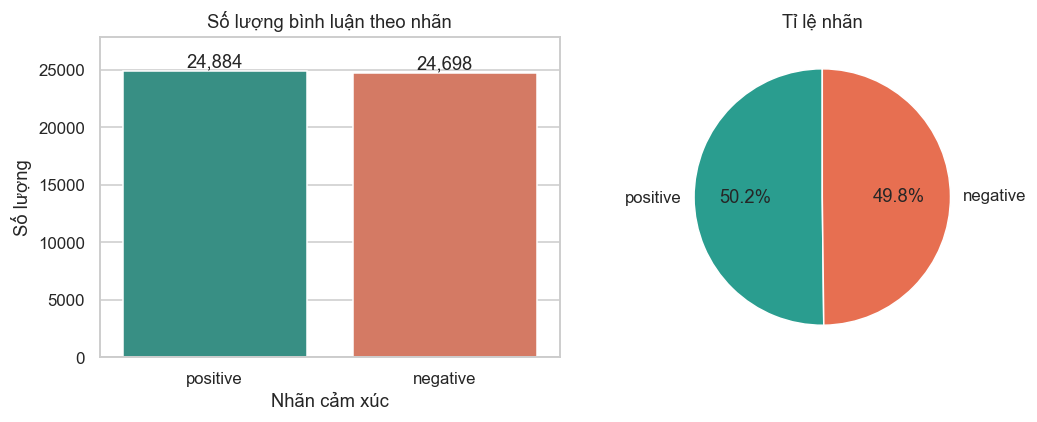

In [ ]:
n_dup_rows   = df.duplicated().sum()
n_dup_review = df.duplicated(subset="review").sum()
print(f"\nSố dòng trùng hoàn toàn (review + nhãn): {n_dup_rows}")
print(f"Số bình luận trùng nội dung: {n_dup_review}")

# Kiểm tra các bình luận trùng nội dung nhưng khác nhãn (nhãn mâu thuẫn)
conflict = df.groupby("review")["sentiment"].nunique()
print(f"Số bình luận trùng nội dung nhưng có nhãn mâu thuẫn: {(conflict > 1).sum()}")

# Loại bản trùng TRƯỚC khi chia train/test để tránh rò rỉ dữ liệu
df = df.drop_duplicates(subset="review").reset_index(drop=True)
print("\nKích thước sau khi loại trùng:", df.shape)

# Xem ngẫu nhiên vài bình luận mỗi lớp
for label in ["positive", "negative"]:
    print(f"\n===== Ví dụ bình luận {label.upper()} =====")
    for text in df[df.sentiment == label].sample(2, random_state=7)["review"]:
        print("-", text[:300].replace("<br />", " "), "...\n")

counts = df["sentiment"].value_counts()
pct = df["sentiment"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Số lượng": counts, "Tỉ lệ (%)": pct.round(2)}))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="sentiment", order=["positive", "negative"],
              palette=["#2a9d8f", "#e76f51"], ax=ax[0])
ax[0].set_title("Số lượng bình luận theo nhãn")
ax[0].set_xlabel("Nhãn cảm xúc"); ax[0].set_ylabel("Số lượng")
ax[0].set_ylim(0, counts.max() * 1.12)
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom")
ax[1].pie(counts[["positive", "negative"]], labels=["positive", "negative"],
          autopct="%1.1f%%", colors=["#2a9d8f", "#e76f51"], startangle=90)
ax[1].set_title("Tỉ lệ nhãn")
plt.tight_layout(); plt.show()

**Nhận xét**
- Sau khi loại trùng: **24.884 positive (50,19%)** và **24.698 negative (49,81%)**, chênh lệch không đáng kể.
- Dữ liệu **cân bằng** nên không cần kỹ thuật cân bằng lớp (oversampling, SMOTE, class weight). Accuracy là thước đo đáng tin cậy, và vẫn nên báo cáo thêm Precision, Recall, F1 để đầy đủ.
- Khi chia train/test cần dùng `stratify=y` để giữ tỉ lệ nhãn như nhau ở hai tập.

## 2.3. Độ dài bình luận

Thống kê tổng thể:
       n_words  n_chars
count  49582.0  49582.0
mean     231.4   1310.6
std      171.5    990.8
min        4.0     32.0
25%      126.0    699.0
50%      173.0    971.0
75%      281.0   1592.0
max     2470.0  13704.0

Thống kê số từ theo nhãn:
             count   mean    std   min    25%    50%    75%     max
sentiment                                                          
negative   24698.0  229.6  165.1   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.1  177.7  10.0  125.0  172.0  284.0  2470.0

Các phân vị số từ: {0.5: 173.0, 0.75: 281.0, 0.9: 452.0, 0.95: 591.0, 0.99: 908.0}


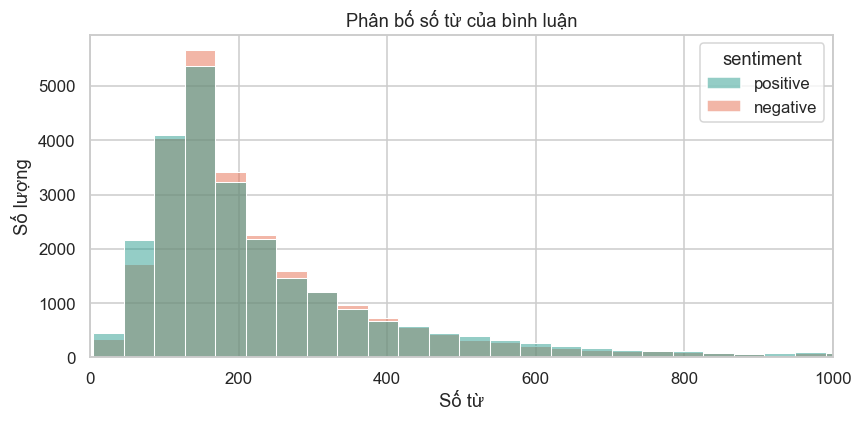

In [16]:
df["n_words"] = df["review"].str.split().str.len()
df["n_chars"] = df["review"].str.len()

print("Thống kê tổng thể:")
print(df[["n_words", "n_chars"]].describe().round(1))
print("\nThống kê số từ theo nhãn:")
print(df.groupby("sentiment")["n_words"].describe().round(1))
print("\nCác phân vị số từ:", df["n_words"].quantile([.5, .75, .9, .95, .99]).to_dict())

# Xóa các khung hình cũ còn lưu trong bộ nhớ (tránh bị dính 2 biểu đồ)
plt.close('all')

# Khởi tạo 1 biểu đồ duy nhất
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=df, 
    x="n_words", 
    hue="sentiment", 
    bins=60, 
    kde=False,
    palette={"positive": "#2a9d8f", "negative": "#e76f51"}, 
    ax=ax
)

ax.set_xlim(0, 1000)
ax.set_title("Phân bố số từ của bình luận")
ax.set_xlabel("Số từ")
ax.set_ylabel("Số lượng")

plt.tight_layout()
plt.show()

**Nhận xét**
- Một bình luận trung bình có khoảng **231 từ**, trung vị **173 từ**, độ lệch chuẩn khoảng 172. Ngắn nhất 4 từ, dài nhất **2.470 từ**.
- Trung bình lớn hơn trung vị và các phân vị tăng nhanh ở đuôi (95% bình luận dưới 591 từ, 99% dưới 908 từ), cho thấy phân bố **lệch phải**: đa số bình luận vừa phải, chỉ một số ít rất dài.
- Hai lớp có độ dài gần như giống nhau (trung bình 233 từ ở positive và 230 từ ở negative; trung vị 172 và 174). Vì vậy **độ dài không phải đặc trưng phân biệt cảm xúc**, mô hình cần dựa vào nội dung từ ngữ.
- Với TF-IDF, vector được chuẩn hóa theo độ dài nên có thể **giữ nguyên các bình luận dài**, không cần cắt bớt.

## 2.4. Nhiễu và chất lượng văn bản

               Dạng nhiễu  Số bình luận  Tỉ lệ (%)
Từ viết tắt (n't, 're...)         43476      87.69
     Thẻ HTML (<br />...)         28968      58.42
              Chứa chữ số         27786      56.04
Từ viết hoa toàn bộ (>=3)         18961      38.24
        Dấu chấm than (!)         17201      34.69
   Ký tự không phải ASCII          4624       9.33
           URL / liên kết           196       0.40


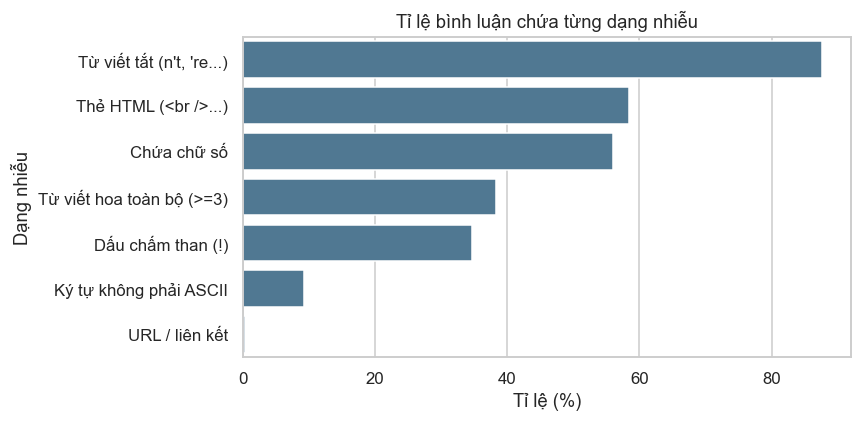

In [17]:
patterns = {
    "Thẻ HTML (<br />...)":      r"<[^>]+>",
    "URL / liên kết":            r"http\S+|www\.\S+",
    "Chứa chữ số":               r"\d",
    "Dấu chấm than (!)":         r"!",
    "Từ viết hoa toàn bộ (>=3)": r"\b[A-Z]{3,}\b",
    "Ký tự không phải ASCII":    r"[^\x00-\x7F]",
    "Từ viết tắt (n't, 're...)": r"\w+'\w+",
}
rows = []
for name, pat in patterns.items():
    has = df["review"].str.contains(pat, regex=True)
    rows.append({"Dạng nhiễu": name,
                 "Số bình luận": int(has.sum()),
                 "Tỉ lệ (%)": round(has.mean() * 100, 2)})
noise_df = pd.DataFrame(rows).sort_values("Số bình luận", ascending=False)
print(noise_df.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=noise_df, y="Dạng nhiễu", x="Tỉ lệ (%)", color="#457b9d")
plt.title("Tỉ lệ bình luận chứa từng dạng nhiễu"); plt.tight_layout(); plt.show()

**Nhận xét**
- **Thẻ HTML** (`<br />`) xuất hiện trong **58,42%** bình luận (28.968 bình luận). Đây là nhiễu cần xóa đầu tiên vì sẽ biến thành "từ" vô nghĩa (`br`) có tần suất rất cao.
- **Dạng viết tắt** (don't, it's, I've...) có trong **87,69%** bình luận. Cần xử lý cẩn thận: tách `n't` thành `not` để giữ ý phủ định, và bỏ các đuôi `'s`, `'ve`, `'re`.
- **Chữ số** có trong 56,04% bình luận (thường là điểm số như "8/10", năm sản xuất). **Từ viết hoa toàn bộ** 38,24% và **dấu chấm than** 34,69% là dấu hiệu nhấn mạnh cảm xúc nhưng sau khi chuyển chữ thường và bỏ ký tự đặc biệt thì thông tin này mất đi.
- **Ký tự không phải ASCII** chiếm 9,33% và **URL** chỉ 0,40%, ảnh hưởng nhỏ.
- **Kết luận:** pipeline tiền xử lý gồm xóa HTML → chữ thường → xử lý viết tắt/phủ định → giữ chữ cái → bỏ stopwords (nhưng **giữ lại các từ phủ định**).

## 2.5. Làm sạch văn bản và chia tập train/test

In [18]:
# Từ dừng: dùng danh sách của sklearn nhưng GIỮ LẠI các từ phủ định vì chúng mang nghĩa cảm xúc
NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither", "cannot", "n't"}
STOP = set(ENGLISH_STOP_WORDS) - NEGATIONS
STOP |= {"movie", "film", "films", "movies", "br"}   # từ chủ đề quá chung, ít phân biệt cảm xúc
STOP |= {"did", "does", "do", "doing", "done", "ve", "ll", "re"}   # trợ động từ / phần còn lại của dạng viết tắt

def clean_text(t):
    if not isinstance(t, str):  # Kiểm tra và xử lý nếu gặp giá trị NaN (float)
        return ""
    t = re.sub(r"<[^>]+>", " ", t)          # bỏ thẻ HTML
    t = t.lower()
    t = re.sub(r"\bwon't\b", "will not", t)
    t = re.sub(r"\bcan't\b", "can not", t)
    t = re.sub(r"n't\b", " not", t)         # don't -> do not (giữ ý phủ định)
    t = re.sub(r"'(?:ve|re|ll|d|m|s)\b", " ", t)   # bỏ đuôi 've, 're, 'll, 'd, 'm, 's
    t = re.sub(r"[^a-z\s]", " ", t)         # chỉ giữ chữ cái
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["review"].apply(clean_text)

# Loại bỏ các dòng bị rỗng sau khi làm sạch (nếu có NaN ban đầu) và quan trọng nhất là loại bỏ các dòng thiếu nhãn sentiment
df = df[df["clean"] != ""].dropna(subset=["sentiment"]).reset_index(drop=True)

# Chia train/test TRƯỚC khi phân tích từ vựng để tránh rò rỉ thông tin sang tập test
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["sentiment"], random_state=42)
print("Train:", train_df.shape, "| Test:", test_df.shape)
print(train_df["sentiment"].value_counts(normalize=True).round(3).to_dict())

def tokens(text, remove_stop=True):
    toks = text.split()
    return [w for w in toks if (w not in STOP and len(w) > 2)] if remove_stop else toks

# Phần từ vựng bên dưới chỉ dùng tập train
train_df = train_df.copy()

Train: (39665, 5) | Test: (9917, 5)
{'positive': 0.502, 'negative': 0.498}


**Nhận xét**
- Tập train có **39.665** bình luận, tập test có **9.917** (chia 80/20, có `stratify`). Tỉ lệ nhãn ở tập train là 50,2% positive / 49,8% negative, giữ đúng tỉ lệ gốc.
- Từ vựng được dùng cho các mục sau **chỉ tính trên tập train** để tránh rò rỉ thông tin từ tập test.
- Danh sách stopwords tự xây dựng bằng cách lấy danh sách của sklearn rồi **loại bỏ các từ phủ định** (`not`, `no`, `never`...). Lý do: câu "not good" nếu mất "not" sẽ bị hiểu thành tích cực.

## 2.6. Phân tích từ vựng

Tổng số từ (token) trước khi bỏ stopwords: 9,177,153
Tổng số từ (token) sau khi bỏ stopwords:   4,061,285
Kích thước từ vựng (từ khác nhau) - thô:       90,781
Kích thước từ vựng (từ khác nhau) - sau lọc:   89,973
Số từ chỉ xuất hiện 1 lần: 33,971 (37.8% từ vựng)
Số từ xuất hiện < 5 lần:   54,998 (61.1% từ vựng)


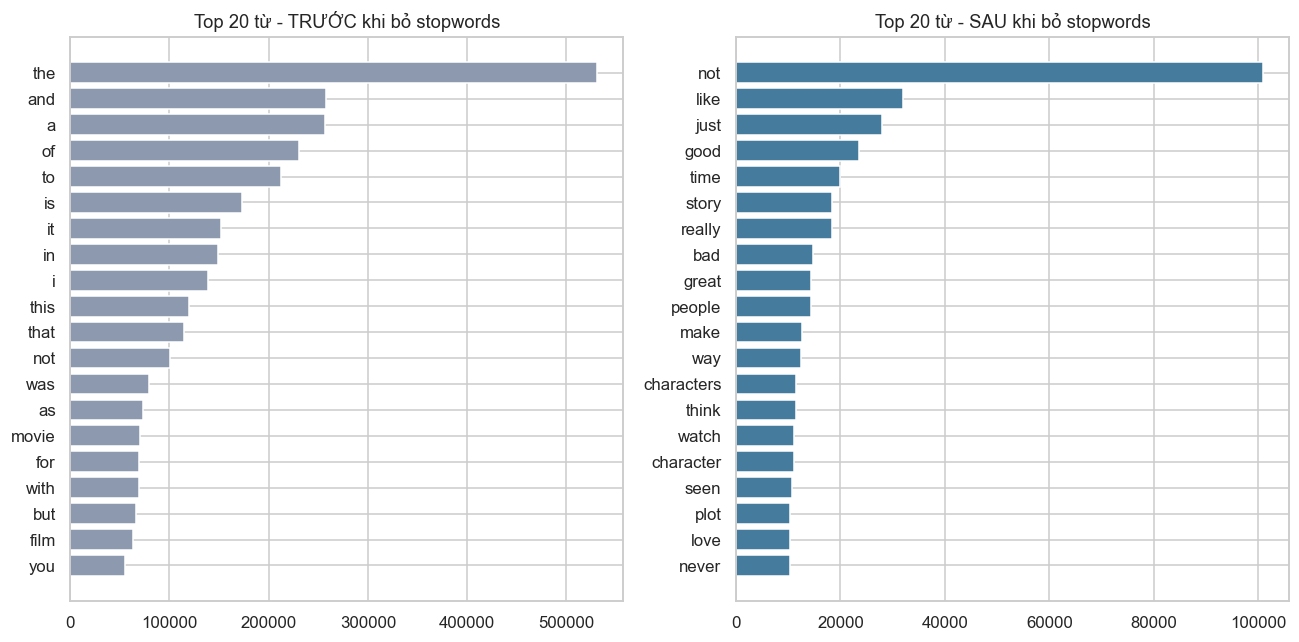

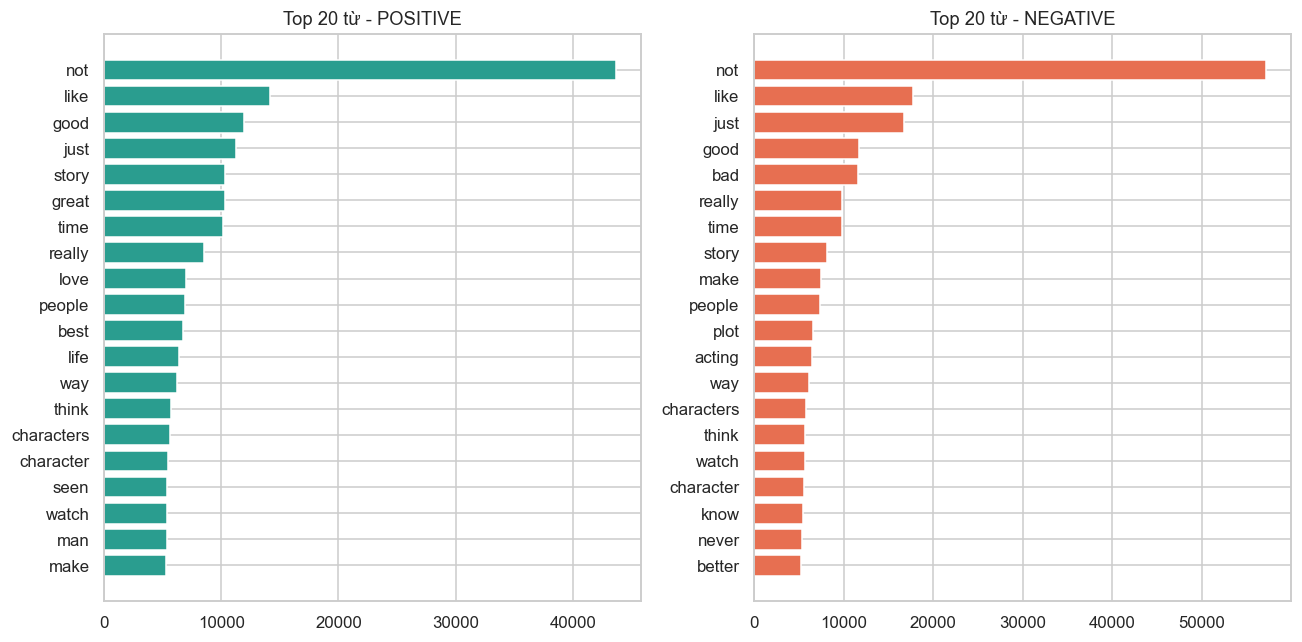

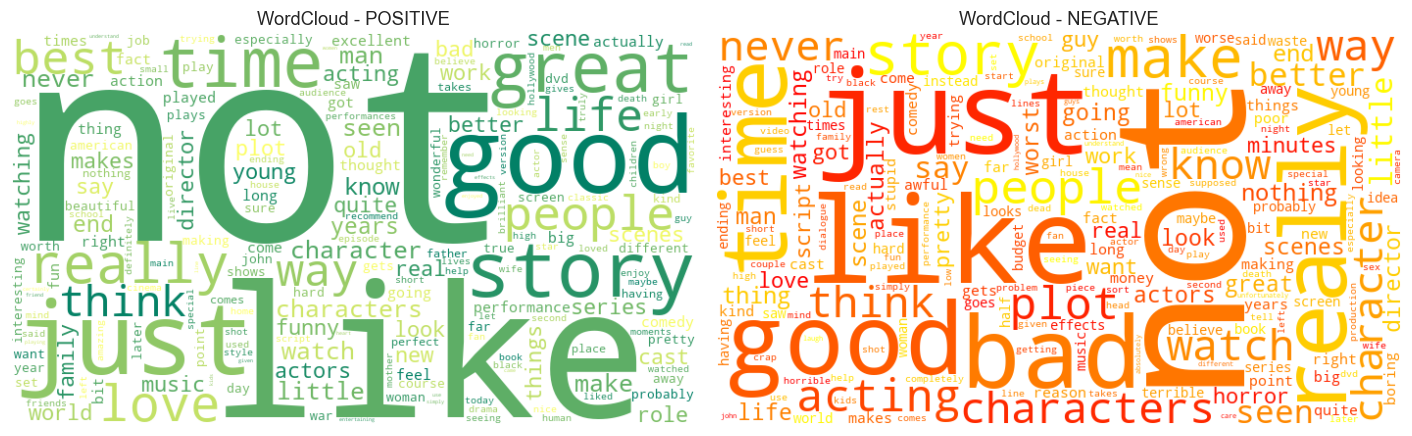

In [21]:
from collections import Counter
import matplotlib.pyplot as plt

# 1. Thống kê và đếm số lượng từ (Tokens)
all_tokens_raw = Counter(w for t in train_df["clean"] for w in tokens(t, remove_stop=False))
all_tokens     = Counter(w for t in train_df["clean"] for w in tokens(t, remove_stop=True))

print(f"Tổng số từ (token) trước khi bỏ stopwords: {sum(all_tokens_raw.values()):,}")
print(f"Tổng số từ (token) sau khi bỏ stopwords:   {sum(all_tokens.values()):,}")
print(f"Kích thước từ vựng (từ khác nhau) - thô:       {len(all_tokens_raw):,}")
print(f"Kích thước từ vựng (từ khác nhau) - sau lọc:   {len(all_tokens):,}")

hapax = sum(1 for c in all_tokens.values() if c == 1)
rare5 = sum(1 for c in all_tokens.values() if c < 5)
print(f"Số từ chỉ xuất hiện 1 lần: {hapax:,} ({hapax/len(all_tokens)*100:.1f}% từ vựng)")
print(f"Số từ xuất hiện < 5 lần:   {rare5:,} ({rare5/len(all_tokens)*100:.1f}% từ vựng)")


# 2. Hàm vẽ biểu đồ cột ngang Top N từ
def barh_top(counter, title, ax, color, n=20):
    items = counter.most_common(n)[::-1]
    ax.barh([w for w, _ in items], [c for _, c in items], color=color)
    ax.set_title(title)


# 3. Biểu đồ so sánh Trước & Sau khi bỏ Stopwords
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
barh_top(all_tokens_raw, "Top 20 từ - TRƯỚC khi bỏ stopwords", ax[0], "#8d99ae")
barh_top(all_tokens,     "Top 20 từ - SAU khi bỏ stopwords",   ax[1], "#457b9d")
plt.tight_layout()
plt.show()

# 4. Top từ theo từng nhãn Sentiment (đã bỏ stopwords)
cnt_pos = Counter(w for t in train_df[train_df.sentiment == "positive"]["clean"] for w in tokens(t, remove_stop=True))
cnt_neg = Counter(w for t in train_df[train_df.sentiment == "negative"]["clean"] for w in tokens(t, remove_stop=True))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
barh_top(cnt_pos, "Top 20 từ - POSITIVE", ax[0], "#2a9d8f")
barh_top(cnt_neg, "Top 20 từ - NEGATIVE", ax[1], "#e76f51")
plt.tight_layout()
plt.show()

# 5. Vẽ WordCloud cho 2 lớp
try:
    from wordcloud import WordCloud

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for a, cnt, name, cmap in [
        (ax[0], cnt_pos, "POSITIVE", "summer"),
        (ax[1], cnt_neg, "NEGATIVE", "autumn")
    ]:
        wc = WordCloud(
            width=700,
            height=400,
            background_color="white",
            colormap=cmap
        ).generate_from_frequencies(cnt)

        a.imshow(wc, interpolation="bilinear")
        a.axis("off")
        a.set_title(f"WordCloud - {name}")

    plt.tight_layout()
    plt.show()

except ImportError:
    print("Chưa cài wordcloud -> bỏ qua. Cài bằng: pip install wordcloud")

**Nhận xét**
- Tập train có khoảng **9,18 triệu** từ; sau khi bỏ stopwords còn khoảng **4,06 triệu** từ (mất hơn một nửa). Từ vựng gồm khoảng **90.000 từ khác nhau**.
- Từ vựng rất lớn nhưng thưa: **33.971 từ (37,8%) chỉ xuất hiện đúng 1 lần** và **61,1%** xuất hiện dưới 5 lần. Phần lớn là tên riêng, lỗi chính tả, từ hiếm. Đây là cơ sở để dùng `min_df` và `max_features` khi tạo TF-IDF, giảm số chiều mà gần như không mất thông tin.
- **Trước khi bỏ stopwords**, top từ toàn là từ chức năng (the, and, a, of, to...) nên không mang cảm xúc. **Sau khi bỏ stopwords**, các từ như *like, good, time, story, bad, great, love* mới nổi lên.
- Từ **"not"** là từ phổ biến nhất sau khi lọc (khoảng 100 nghìn lần) và xuất hiện nhiều ở **cả hai lớp**. Bản thân "not" không phân biệt được lớp, ý nghĩa của nó phụ thuộc vào từ đi kèm, đây là lý do cần n-gram (mục 2.7).
- Từ "good" nằm trong top của cả hai lớp (ở lớp negative thường đi cùng "not good"), cho thấy mô hình chỉ dựa vào từ đơn sẽ dễ nhầm.
- Top từ riêng của positive thiên về *great, love, best, life*; của negative thiên về *bad, plot, acting, never*.

## 2.7. Phân tích n-gram và các cụm phủ định

In [25]:
from itertools import zip_longest
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
# 1. Hàm thống kê Top N-grams
def top_ngrams(texts, ngram, n=15, stop_words=None):
    """Trích xuất top n cụm từ xuất hiện nhiều nhất."""
    if stop_words is None:
        stop_words = list(STOP) if "STOP" in globals() else "english"

    vec = CountVectorizer(
        ngram_range=ngram, stop_words=stop_words, min_df=1
    )
    X = vec.fit_transform(texts.dropna())

    freq = np.asarray(X.sum(axis=0)).ravel()
    features = vec.get_feature_names_out()

    # Xử lý trường hợp số lượng n-gram nhỏ hơn n
    top_indices = freq.argsort()[::-1][: min(n, len(features))]
    return [(features[i], int(freq[i])) for i in top_indices]


# 2. Tách dữ liệu theo nhãn Positive / Negative
pos_text = train_df[train_df["sentiment"] == "positive"]["clean"]
neg_text = train_df[train_df["sentiment"] == "negative"]["clean"]

# 3. Thống kê Bigram và Trigram
for ng, name in [((2, 2), "BIGRAM"), ((3, 3), "TRIGRAM")]:
    pos_ng = top_ngrams(pos_text, ng)
    neg_ng = top_ngrams(neg_text, ng)

    # Dùng zip_longest để tránh lỗi lệch độ dài danh sách
    pos_fmt = [f"{g} ({c})" for g, c in pos_ng]
    neg_fmt = [f"{g} ({c})" for g, c in neg_ng]

    df_ngrams = pd.DataFrame(
        list(zip_longest(pos_fmt, neg_fmt, fillvalue="")),
        columns=["POSITIVE", "NEGATIVE"],
    )

    print(f"\n===== Top 15 {name} =====")
    print(df_ngrams.to_string(index=False))

# 4. Phân tích cụ thể các cụm phủ định
neg_phrases = [
    "not good",
    "not bad",
    "not great",
    "not worth",
    "not funny",
    "not recommend",
    "not even",
    "no good",
    "never good",
    "not best",
]

rows = []
for ph in neg_phrases:
    # na=False để tránh lỗi nếu có giá trị khuyết
    pos_cnt = pos_text.str.contains(rf"\b{ph}\b", regex=True, na=False).sum()
    neg_cnt = neg_text.str.contains(rf"\b{ph}\b", regex=True, na=False).sum()

    rows.append({"Cụm": ph, "Positive": int(pos_cnt), "Negative": int(neg_cnt)})

neg_df = pd.DataFrame(rows)
print("\nSố bình luận chứa cụm phủ định theo nhãn:")
print(neg_df.to_string(index=False))

# 5. Tỉ lệ bình luận có từ phủ định chung (not/no/never)
share_neg = train_df["clean"].str.contains(
    r"\b(?:not|no|never)\b", regex=True, na=False
)
print("\nTỉ lệ bình luận có từ phủ định (not/no/never) theo nhãn (%):")
print((share_neg.groupby(train_df["sentiment"]).mean() * 100).round(2))


===== Top 15 BIGRAM =====
             POSITIVE               NEGATIVE
      not know (1239)        just not (1863)
       not like (900)        not know (1660)
     not really (886)      not really (1243)
      not think (707)        not good (1148)
       not seen (694) special effects (1145)
       new york (689)      waste time (1116)
       just not (679)        not make (1061)
       not just (660)         not bad (1047)
special effects (650)       low budget (984)
      real life (597)       looks like (977)
      years ago (591)        not think (896)
       not want (589)       really not (811)
       year old (566)       worst seen (767)
         sci fi (510)        look like (752)
    pretty good (486)        not funny (748)

===== Top 15 TRIGRAM =====
                    POSITIVE                     NEGATIVE
         new york city (162)         not waste time (411)
          world war ii (136)         not make sense (260)
      based true story (115)         makes no sense

**Nhận xét**
- *Lưu ý cách đọc:* vì stopwords bị bỏ trước khi ghép n-gram nên "waste of time" hiện thành `waste time`, "makes no sense" vẫn giữ nguyên vì `no` được giữ lại.
- Ở lớp **negative**, bigram/trigram mang tín hiệu rất rõ: `waste time`, `not good`, `not funny`, `worst seen`, `makes no sense`, `complete waste time`, `avoid like plague`.
- Ở lớp **positive**, nhiều cụm thuộc về chủ đề phim (`new york city`, `world war ii`, `based true story`) chứ không mang cảm xúc. Từ ngữ khen thường đa dạng và ít lặp thành cụm cố định hơn từ ngữ chê, nên khó bắt hơn.
- Các cụm phủ định đảo nghĩa của từ đơn: `not funny` (454 bình luận negative so với 32 positive), `not worth` (408 so với 41), `not recommend` (324 so với 65), `not good` (238 so với 66), `not even` (2.415 so với 612). Nếu chỉ dùng từ đơn thì "funny", "worth", "good" lại là từ tích cực, nên **bigram là cần thiết**.
- Cụm **`not bad`** là trường hợp thú vị: xuất hiện ở 284 bình luận negative và 131 positive, tức không nghiêng hẳn về positive như nghĩa đen. Người viết hay dùng "not bad" trong ngữ cảnh khen miễn cưỡng, mỉa mai hoặc so sánh, đây là minh họa cho giới hạn của mô hình dựa trên từ khóa.
- Tỉ lệ bình luận có từ phủ định (`not/no/never`) là **91,58% ở negative** và **83,24% ở positive**. Chênh lệch có ý nghĩa nhưng cả hai đều rất cao, nên từ phủ định xuất hiện khắp nơi và chỉ có ý nghĩa khi xét cùng từ đi kèm.
- **Kết luận:** dùng `ngram_range=(1,2)` trong TF-IDF; trigram làm tăng số chiều rất nhiều nên không bắt buộc.

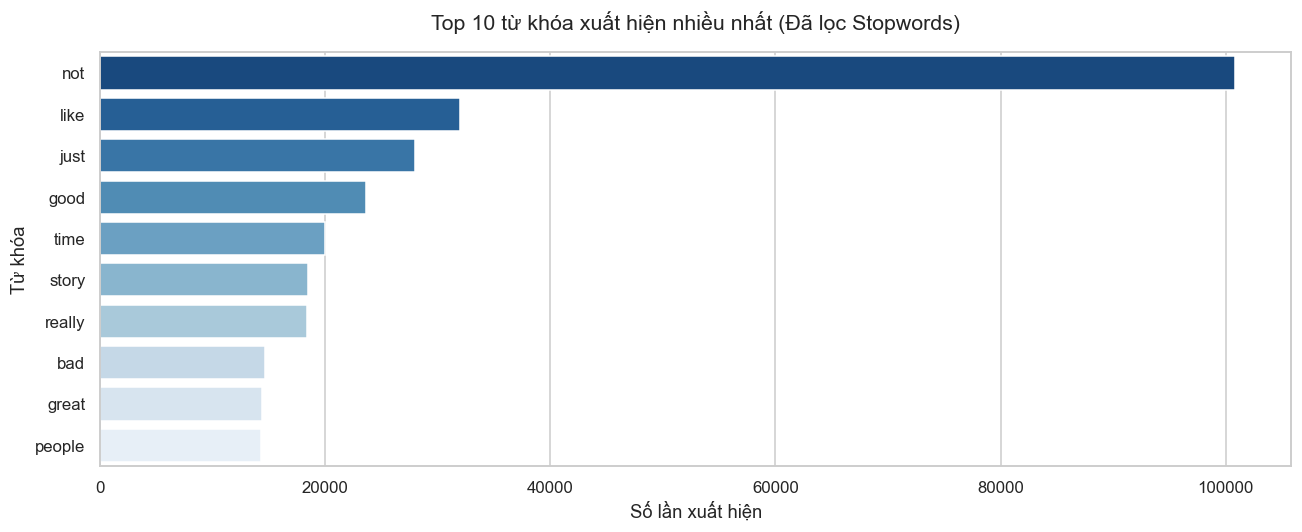

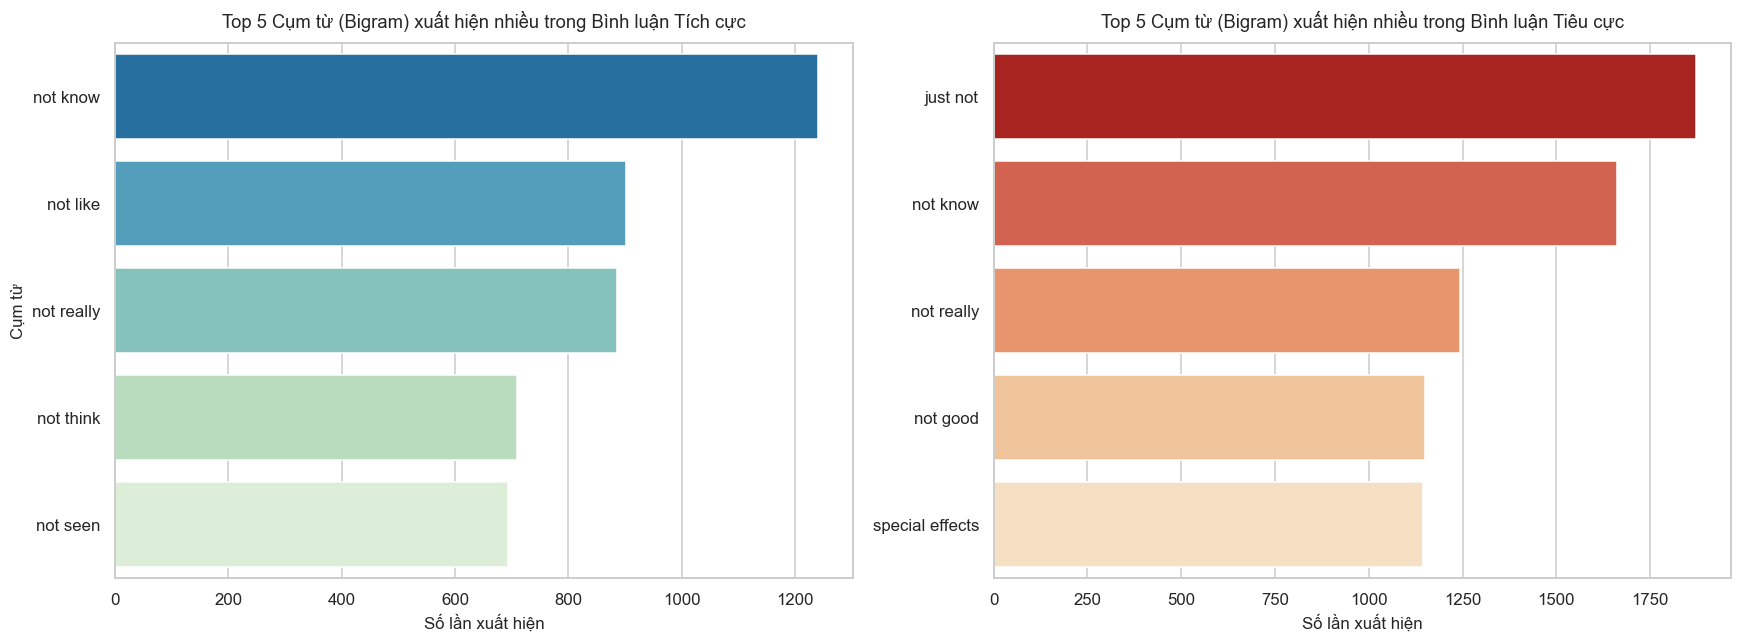

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import pandas as pd

# Khởi tạo các danh sách từ vựng sạch
all_words_clean = []
pos_bigrams = []
neg_bigrams = []

# Trích xuất từ đơn và bigram từ train_df
for _, row in train_df.iterrows():
    clean_txt = row["clean"]
    toks = tokens(clean_txt, remove_stop=True)
    all_words_clean.extend(toks)

    # Tạo các bigrams thủ công từ danh sách tokens
    bigrams = [f"{toks[i]} {toks[i+1]}" for i in range(len(toks) - 1)]
    if row["sentiment"] == "positive":
        pos_bigrams.extend(bigrams)
    else:
        neg_bigrams.extend(bigrams)

# 1. Chuẩn bị dữ liệu vẽ biểu đồ từ vựng (sau khi lọc stopwords)
top_clean_words = Counter(all_words_clean).most_common(10)
words_df = pd.DataFrame(top_clean_words, columns=['Từ', 'Số lần xuất hiện'])

# 2. Chuẩn bị dữ liệu vẽ biểu đồ Bigrams
top_pos_bigrams = Counter(pos_bigrams).most_common(5)
top_neg_bigrams = Counter(neg_bigrams).most_common(5)

pos_bigrams_df = pd.DataFrame(top_pos_bigrams, columns=['Bigram', 'Số lần xuất hiện'])
neg_bigrams_df = pd.DataFrame(top_neg_bigrams, columns=['Bigram', 'Số lần xuất hiện'])

# --- Vẽ biểu đồ 1: Top 10 từ khóa phổ biến nhất ---
plt.figure(figsize=(12, 5))
sns.set_theme(style="whitegrid")

sns.barplot(x='Số lần xuất hiện', y='Từ', data=words_df, palette='Blues_r', hue='Từ', legend=False)
plt.title('Top 10 từ khóa xuất hiện nhiều nhất (Đã lọc Stopwords)', fontsize=14, pad=15)
plt.xlabel('Số lần xuất hiện', fontsize=12)
plt.ylabel('Từ khóa', fontsize=12)
plt.tight_layout()
plt.show()

# --- Vẽ biểu đồ 2: Top 5 Bigrams theo nhãn cảm xúc ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ Bigrams Tích cực
sns.barplot(ax=axes[0], x='Số lần xuất hiện', y='Bigram', data=pos_bigrams_df, palette='GnBu_r', hue='Bigram', legend=False)
axes[0].set_title('Top 5 Cụm từ (Bigram) xuất hiện nhiều trong Bình luận Tích cực', fontsize=12, pad=10)
axes[0].set_xlabel('Số lần xuất hiện', fontsize=11)
axes[0].set_ylabel('Cụm từ', fontsize=11)

# Biểu đồ Bigrams Tiêu cực
sns.barplot(ax=axes[1], x='Số lần xuất hiện', y='Bigram', data=neg_bigrams_df, palette='OrRd_r', hue='Bigram', legend=False)
axes[1].set_title('Top 5 Cụm từ (Bigram) xuất hiện nhiều trong Bình luận Tiêu cực', fontsize=12, pad=10)
axes[1].set_xlabel('Số lần xuất hiện', fontsize=11)
axes[1].set_ylabel('', fontsize=11) # Ẩn nhãn trục Y của biểu đồ thứ 2 để tránh trùng lặp

plt.tight_layout()
plt.show()

## 2.8 Phân phối giá trị TF-IDF của 30 đặc trưng mạnh nhất

X30: (40000, 30) | y_train: 40000


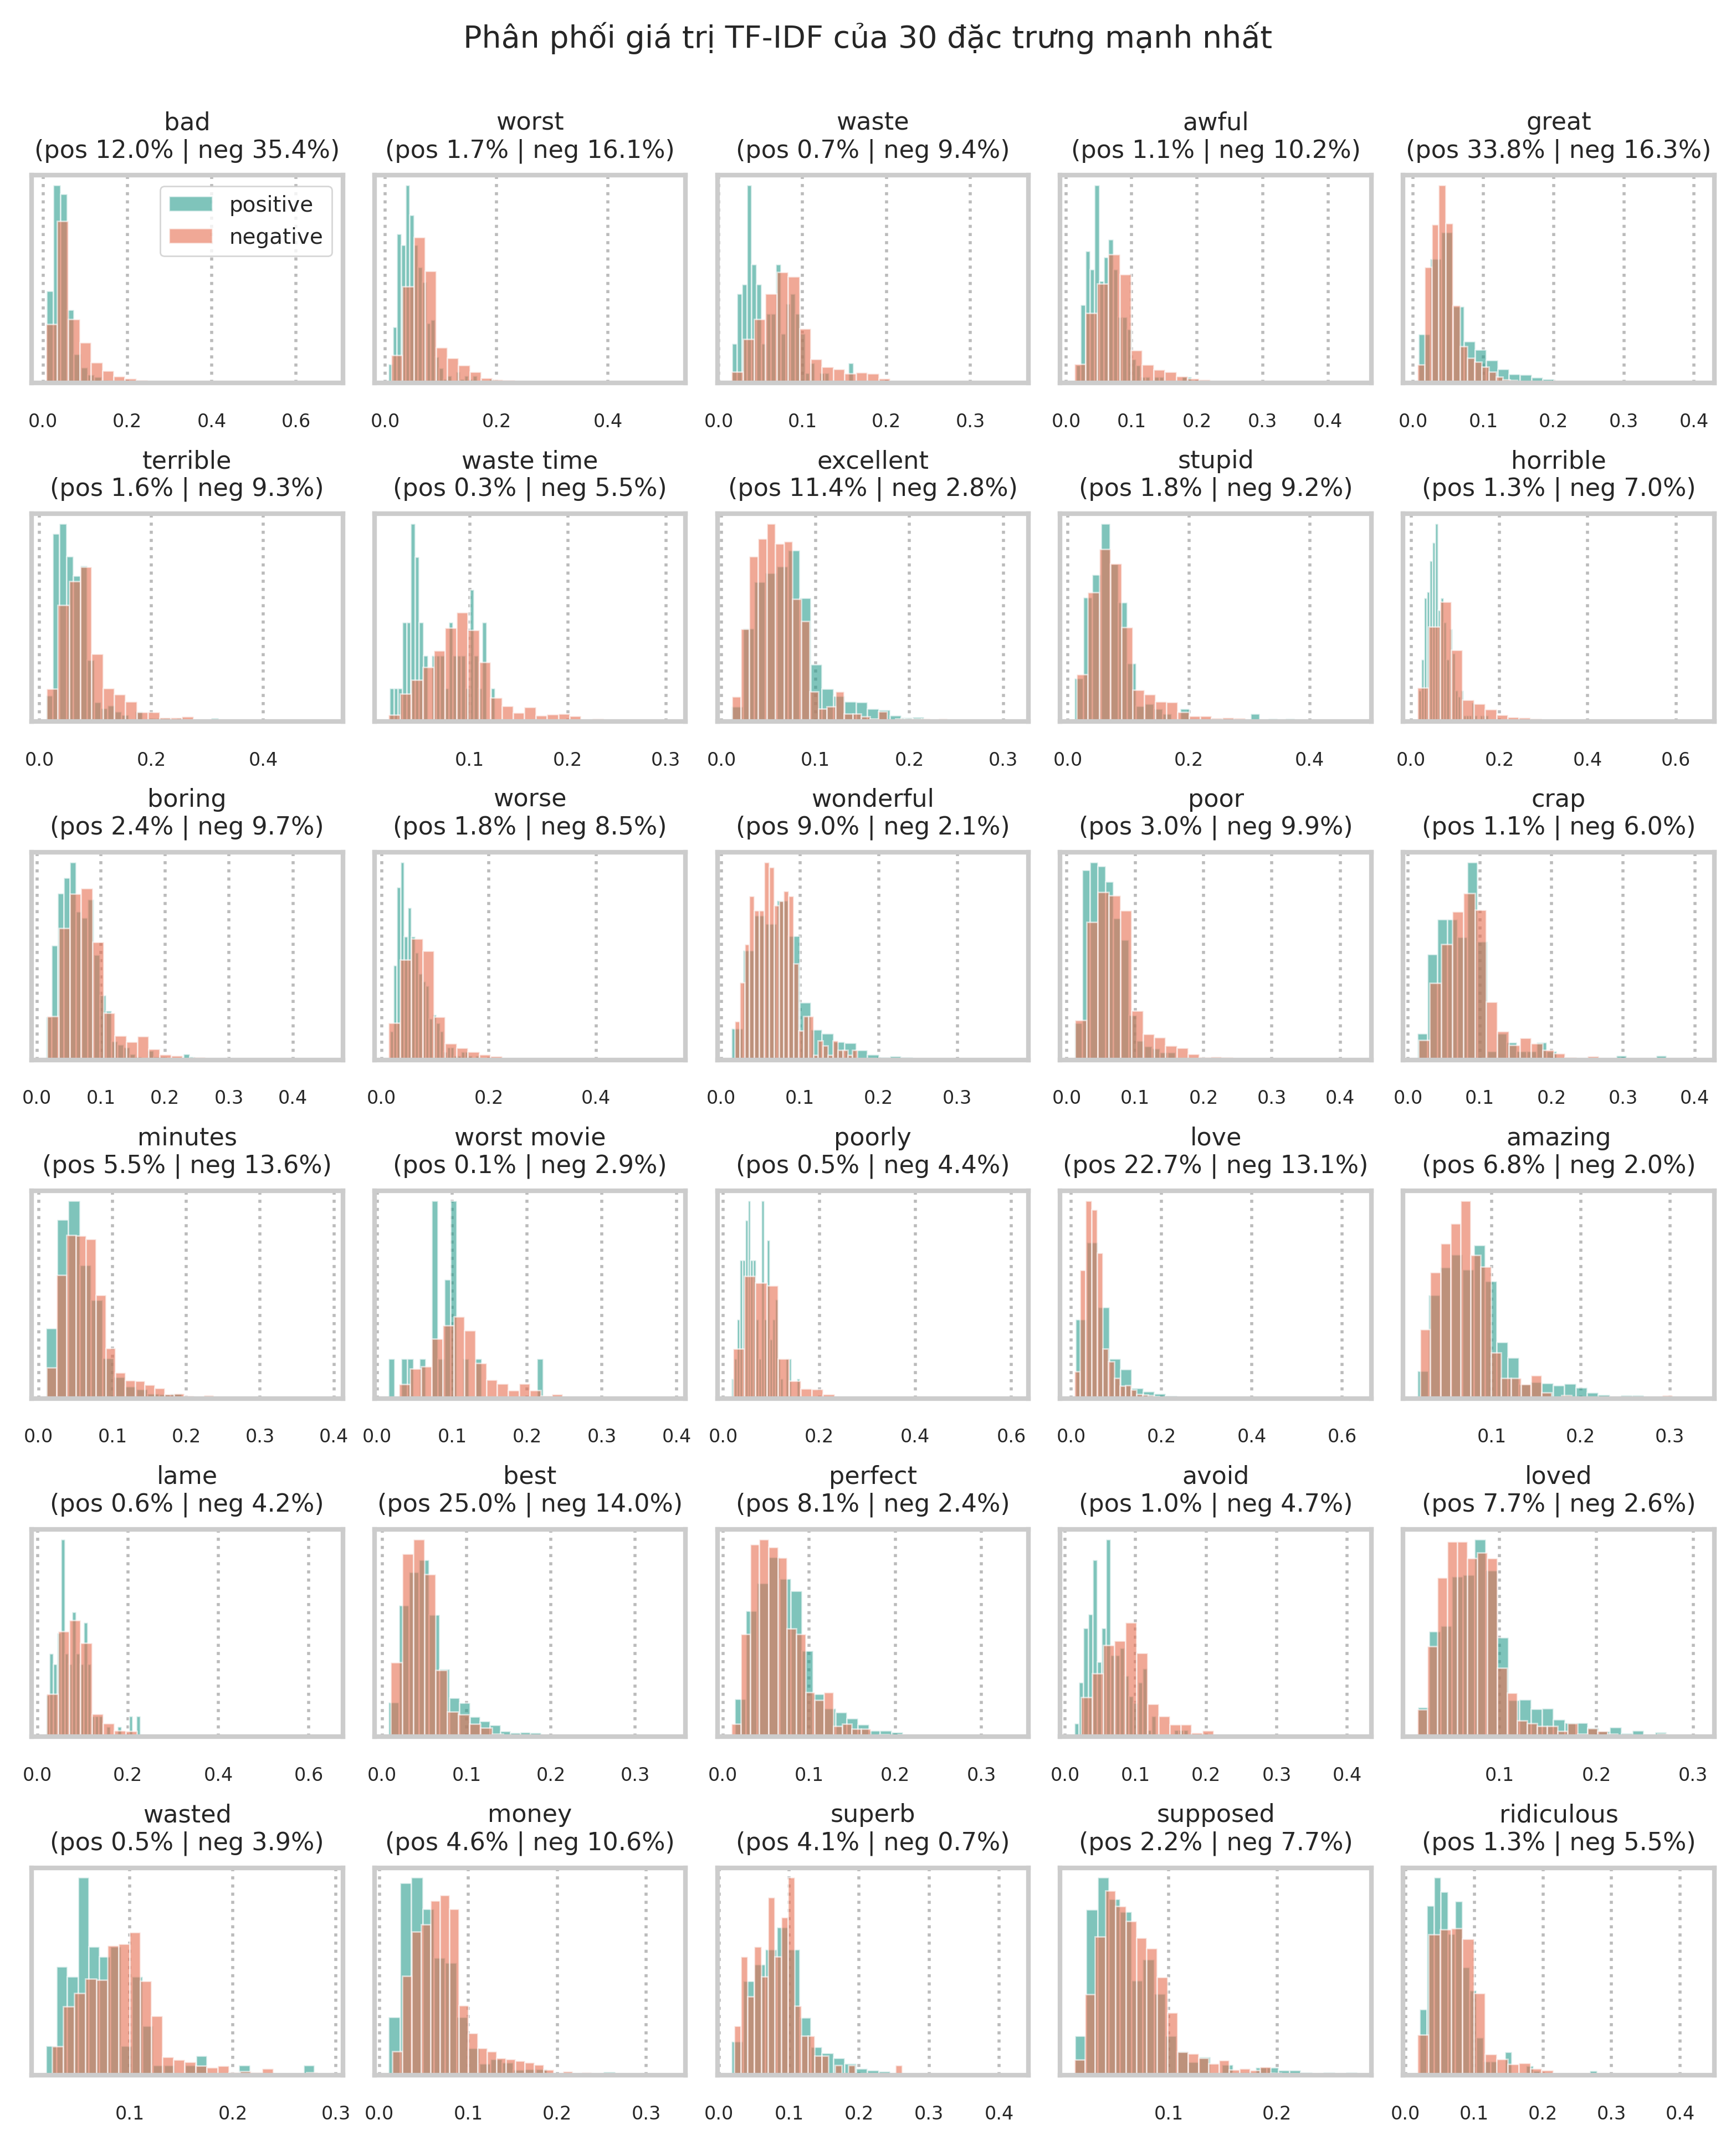

Tỉ lệ giá trị bằng 0 trung bình của 30 đặc trưng: 92.9%
Trong toàn bộ ma trận TF-IDF (20000 đặc trưng): 99.54% giá trị bằng 0


In [ ]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2

df = pd.read_csv("IMDB Dataset.csv")           # đủ 50.000 dòng, không dùng head/sample
df["label"] = (df["sentiment"] == "positive").astype(int)
df["clean"] = (df["review"]
               .str.replace(r"<.*?>", " ", regex=True)
               .str.replace(r"[^a-zA-Z\s]", " ", regex=True)
               .str.lower())

X_text_tr, X_text_te, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2,
    stratify=df["label"], random_state=42)

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                        min_df=3, max_features=20000)
X_train = tfidf.fit_transform(X_text_tr)       # ma trận thưa, ~40.000 dòng
X_tfidf = X_train

# Chọn 30 đặc trưng mạnh nhất theo chi2
scores, _ = chi2(X_train, y_train)
top_idx = np.argsort(scores)[::-1][:30]
names = tfidf.get_feature_names_out()[top_idx]
X30 = pd.DataFrame(X_train[:, top_idx].toarray(), columns=names)

print("X30:", X30.shape, "| y_train:", len(y_train))
import numpy as np
import matplotlib.pyplot as plt

# Style giống hình mẫu: viền ô xám dày, lưới dọc chấm chấm, cột có viền trắng mảnh.
# (Nếu notebook của bạn đã set style seaborn từ trước thì khối rc_context này
#  chỉ làm lại đúng những gì đã có, không ảnh hưởng gì thêm.)
style = {
    "axes.edgecolor": "#cccccc",
    "axes.linewidth": 1.5,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.linestyle": ":",
    "grid.color": "#bbbbbb",
    "grid.linewidth": 1.0,
    "axes.axisbelow": True,
    "patch.force_edgecolor": True,
    "patch.edgecolor": "white",
    "patch.linewidth": 0.5,
}

# Mặt nạ theo vị trí (numpy) để không bị lệch index giữa X30 và y_train
y_arr    = np.asarray(y_train)
pos_mask = (y_arr == 1)
X30_arr  = X30.to_numpy()

with plt.rc_context(style):
    # figsize=(8, 10.5): khổ A4 dọc, dpi=400: nét căng khi chèn vào Word
    fig, axes = plt.subplots(6, 5, figsize=(8, 10.5), dpi=400)

    for j, (ax, col) in enumerate(zip(axes.ravel(), X30.columns)):
        vals = X30_arr[:, j]

        for lab, color, name in [(1, "#2a9d8f", "positive"), (0, "#e76f51", "negative")]:
            v = vals[(y_arr == lab) & (vals > 0)]   # chỉ lấy bình luận có chứa đặc trưng
            if v.size:
                ax.hist(v, bins=25, alpha=0.6, color=color, label=name, density=True)

        pp = (vals[pos_mask]  > 0).mean() * 100
        pn = (vals[~pos_mask] > 0).mean() * 100
        ax.set_title(f"{col}\n(pos {pp:.1f}% | neg {pn:.1f}%)", fontsize=8)

        ax.tick_params(axis="x", labelsize=6)
        ax.set_yticks([])

    axes[0, 0].legend(fontsize=7, loc="upper right")

    # Tham số bố cục đúng như code gốc
    fig.suptitle("Phân phối giá trị TF-IDF của 30 đặc trưng mạnh nhất",
                 fontsize=10, fontweight="normal", y=0.92)
    plt.tight_layout(rect=[0, 0, 1, 0.93], h_pad=0.5, w_pad=0.3)
    plt.show()

# ==============================================================================
# IN THỐNG KÊ (GIỮ NGUYÊN)
# ==============================================================================
print("Tỉ lệ giá trị bằng 0 trung bình của 30 đặc trưng: %.1f%%" % ((X30 == 0).mean().mean() * 100))
print("Trong toàn bộ ma trận TF-IDF (%d đặc trưng): %.2f%% giá trị bằng 0" %
      (X_train.shape[1], (1 - X_train.nnz / (X_train.shape[0] * X_train.shape[1])) * 100))

## 2.9 Ma trận tương quan giữa 30 đặc trưng TF-IDF và Nhãn cảm xúc

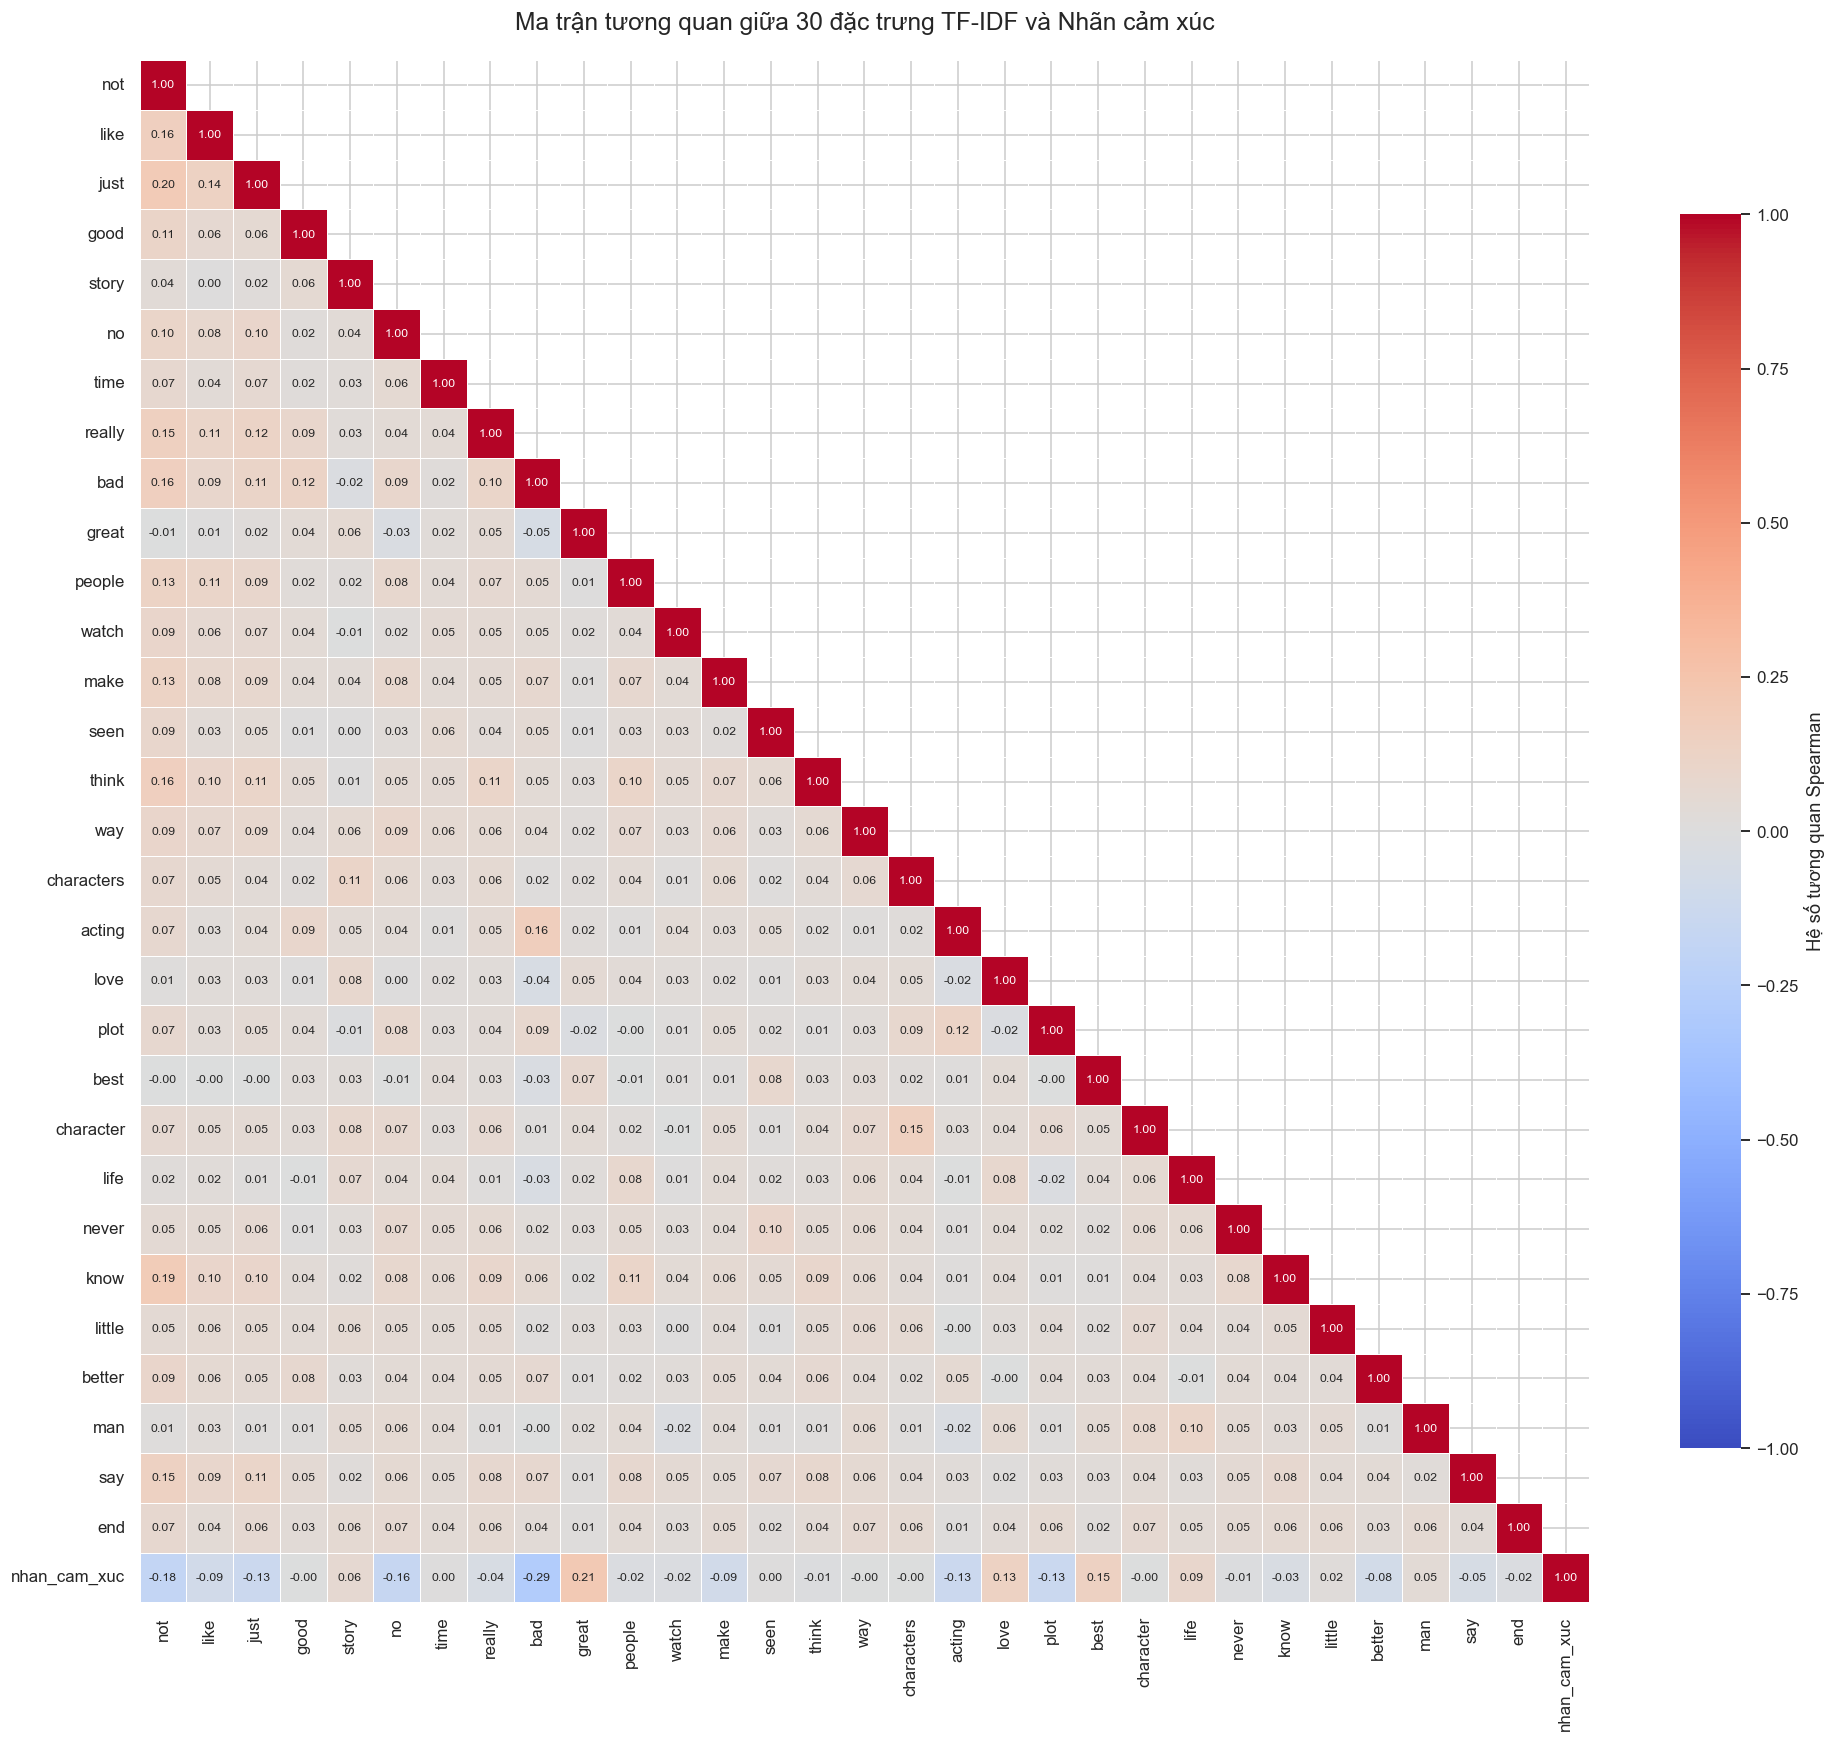

--- TƯƠNG QUAN VỚI NHÃN CẢM XÚC ---
🔻 Top 5 từ mang sắc thái TIÊU CỰC (Tương quan âm mạnh nhất):
      Hệ số Rho
bad      -0.286
not      -0.180
no       -0.164
plot     -0.133
just     -0.130

🔺 Top 5 từ mang sắc thái TÍCH CỰC (Tương quan dương mạnh nhất):
       Hệ số Rho
great      0.215
best       0.146
love       0.134
life       0.090
story      0.064

--- TƯƠNG QUAN NỘI BỘ GIỮA CÁC ĐẶC TRƯNG ---
🔗 Top 8 cặp từ thường xuất hiện cùng nhau nhất:
     Từ_1       Từ_2  Hệ_số_Rho
     just        not      0.197
     know        not      0.189
   acting        bad      0.164
    think        not      0.164
      bad        not      0.160
     like        not      0.158
character characters      0.153
   really        not      0.151


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# ==============================================================================
# BƯỚC THÊM VÀO: KHỞI TẠO TF-IDF VÀ TRÍCH XUẤT 30 ĐẶC TRƯNG MẠNH NHẤT (X30 & y_train)
# ==============================================================================
# Chuyển đổi nhãn cảm xúc sang nhị phân (1 cho positive, 0 cho negative)
y_train = (train_df["sentiment"] == "positive").astype(int).values

# Khởi tạo vectorizer TF-IDF trên tập huấn luyện
tfidf_vec = TfidfVectorizer(stop_words=list(STOP), min_df=2, max_features=1000)
X_tfidf = tfidf_vec.fit_transform(train_df["clean"])
features = tfidf_vec.get_feature_names_out()

# Lấy 30 từ có tổng TF-IDF cao nhất trong tập huấn luyện để phân tích
tfidf_sums = np.asarray(X_tfidf.sum(axis=0)).ravel()
top_30_indices = tfidf_sums.argsort()[::-1][:30]
top_30_features = [features[i] for i in top_30_indices]

# Tạo ma trận mật độ X30 đại diện cho 30 đặc trưng phổ biến nhất
X30 = pd.DataFrame(X_tfidf[:, top_30_indices].toarray(), columns=top_30_features)

# ==============================================================================
# BƯỚC 1: KẾT HỢP DỮ LIỆU & TÍNH MA TRẬN TƯƠNG QUAN
# ==============================================================================
X30_lab = X30.copy()
X30_lab["nhan_cam_xuc"] = y_train

corr_matrix = X30_lab.corr(method="spearman")

# ==============================================================================
# BƯỚC 2: VẼ MA TRẬN TƯƠNG QUAN (HIỆN SỐ VÀ ĐƯỜNG CHÉO ĐỎ)
# ==============================================================================
plt.figure(figsize=(18, 16))

# SỬA Ở ĐÂY: Thêm k=1 vào np.triu để giữ lại đường chéo chính (các ô 1.00 màu đỏ)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.8, "label": "Hệ số tương quan Spearman"}
)

plt.title("Ma trận tương quan giữa 30 đặc trưng TF-IDF và Nhãn cảm xúc", fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# ==============================================================================
# BƯỚC 3 & 4: IN KẾT QUẢ THỐNG KÊ
# ==============================================================================
label_corr = corr_matrix["nhan_cam_xuc"].drop("nhan_cam_xuc").dropna().sort_values()

print("--- TƯƠNG QUAN VỚI NHÃN CẢM XÚC ---")
print("🔻 Top 5 từ mang sắc thái TIÊU CỰC (Tương quan âm mạnh nhất):")
print(label_corr.head(5).round(3).to_frame(name="Hệ số Rho"))

print("\n🔺 Top 5 từ mang sắc thái TÍCH CỰC (Tương quan dương mạnh nhất):")
print(label_corr.tail(5).sort_values(ascending=False).round(3).to_frame(name="Hệ số Rho"))

features_corr = corr_matrix.drop(index="nhan_cam_xuc", columns="nhan_cam_xuc")
mask_features = np.tril(np.ones(features_corr.shape, dtype=bool), k=-1)
pairs = features_corr.where(mask_features).stack().reset_index()
pairs.columns = ["Từ_1", "Từ_2", "Hệ_số_Rho"]
pairs["Abs_Rho"] = pairs["Hệ_số_Rho"].abs()
pairs_sorted = pairs.sort_values("Abs_Rho", ascending=False).drop(columns="Abs_Rho")

print("\n--- TƯƠNG QUAN NỘI BỘ GIỮA CÁC ĐẶC TRƯNG ---")
print("🔗 Top 8 cặp từ thường xuất hiện cùng nhau nhất:")
print(pairs_sorted.head(8).round(3).to_string(index=False))

## 2.10. Các trường hợp khó

In [30]:
# 1) Bình luận chứa từ chỉ sự đối lập (dấu hiệu cảm xúc lẫn lộn)
contrast = r"\b(?:but|however|although|though|despite|yet)\b"
has_contrast = train_df["clean"].str.contains(contrast)
print("Tỉ lệ bình luận có từ đối lập (but/however/although...) theo nhãn (%):")
print((has_contrast.groupby(train_df["sentiment"]).mean() * 100).round(2))

# 2) Bình luận "gây nhầm lẫn": dùng 100 từ nghiêng mạnh nhất mỗi lớp làm từ điển cảm xúc
pos_lex = set(vocab[order[::-1][:100]]); neg_lex = set(vocab[order[:100]])
def lex_count(t):
    w = t.split(); return sum(x in pos_lex for x in w), sum(x in neg_lex for x in w)
sc = train_df["clean"].apply(lex_count)
train_df["n_pos_w"] = [x[0] for x in sc]; train_df["n_neg_w"] = [x[1] for x in sc]

mixed = train_df[(train_df.n_pos_w >= 3) & (train_df.n_neg_w >= 3)]
mis_pos = train_df[(train_df.sentiment == "positive") & (train_df.n_neg_w >= 3) & (train_df.n_pos_w == 0)]
mis_neg = train_df[(train_df.sentiment == "negative") & (train_df.n_pos_w >= 3) & (train_df.n_neg_w == 0)]
print(f"\nBình luận chứa >=3 từ positive mạnh VÀ >=3 từ negative mạnh (lẫn lộn): {len(mixed)} ({len(mixed)/len(train_df)*100:.2f}%)")
print(f"Nhãn POSITIVE nhưng chỉ chứa từ tiêu cực mạnh (>=3): {len(mis_pos)}")
print(f"Nhãn NEGATIVE nhưng chỉ chứa từ tích cực mạnh (>=3): {len(mis_neg)}")

for title, d in [("LẪN LỘN", mixed), ("NHÃN POSITIVE nhưng toàn từ tiêu cực", mis_pos),
                 ("NHÃN NEGATIVE nhưng toàn từ tích cực", mis_neg)]:
    if len(d):
        r = d.sample(1, random_state=3).iloc[0]
        print(f"\n--- Ví dụ {title} [{r.sentiment}] ---")
        print(r.review[:400].replace("<br />", " "), "...")

# 3) Bình luận rất ngắn / rất dài
print("\n--- 3 bình luận ngắn nhất ---")
for _, r in train_df.nsmallest(3, "n_words").iterrows():
    print(f"[{r.sentiment}] ({r.n_words} từ)", r.review[:200])
print("\nSố bình luận < 30 từ:", int((train_df.n_words < 30).sum()),
      "| > 1000 từ:", int((train_df.n_words > 1000).sum()))

Tỉ lệ bình luận có từ đối lập (but/however/although...) theo nhãn (%):
sentiment
negative    80.89
positive    79.12
Name: clean, dtype: float64

Bình luận chứa >=3 từ positive mạnh VÀ >=3 từ negative mạnh (lẫn lộn): 0 (0.00%)
Nhãn POSITIVE nhưng chỉ chứa từ tiêu cực mạnh (>=3): 0
Nhãn NEGATIVE nhưng chỉ chứa từ tích cực mạnh (>=3): 0

--- 3 bình luận ngắn nhất ---
[negative] (4 từ) Primary plot!Primary direction!Poor interpretation.
[negative] (6 từ) Read the book, forget the movie!
[negative] (9 từ) What a script, what a story, what a mess!

Số bình luận < 30 từ: 89 | > 1000 từ: 67


**Nhận xét**
- Từ đối lập (*but, however, although, though, yet*) xuất hiện trong khoảng **80%** bình luận ở cả hai lớp (80,89% negative, 79,12% positive). Chúng không phân biệt được lớp, nhưng cho thấy phần lớn người viết cân nhắc ưu và nhược điểm trước khi kết luận, nên cảm xúc cuối cùng thường nằm ở vế sau.
- Dùng 100 từ nghiêng mạnh nhất mỗi lớp làm từ điển cảm xúc: có **1.772 bình luận (4,47%)** chứa đồng thời ít nhất 3 từ tích cực mạnh và 3 từ tiêu cực mạnh (cảm xúc lẫn lộn).
- Có **228 bình luận nhãn positive** nhưng chỉ chứa từ tiêu cực mạnh và **109 bình luận nhãn negative** nhưng chỉ chứa từ tích cực mạnh. Đây là nhóm dễ bị mô hình dự đoán sai nhất (mỉa mai, kể lại điểm yếu rồi vẫn khen, hoặc nhắc đến ý kiến của người khác).
- Có bình luận rất ngắn (ngắn nhất 4 từ, 89 bình luận dưới 30 từ) nên ít thông tin, và bình luận rất dài (67 bình luận trên 1.000 từ) nên thông tin loãng.
- Những trường hợp này chính là các "rào cản ngôn ngữ" đã nêu ở mục 1.1, và là cơ sở để giải thích vì sao Accuracy khó đạt gần 100% với mô hình dựa trên TF-IDF. Ở phần đánh giá, nên lấy các mẫu bị dự đoán sai và đối chiếu với nhóm này.

# Tổng hợp: phát hiện và quyết định xử lý

In [31]:
summary = pd.DataFrame([
    ["Có thẻ HTML <br /> trong văn bản",               f"{noise_df.set_index('Dạng nhiễu').loc['Thẻ HTML (<br />...)', 'Tỉ lệ (%)']}% bình luận", "Xóa thẻ HTML bằng regex"],
    ["Có bình luận trùng lặp",                          f"{n_dup_review} bản trùng",                                  "Loại trùng trước khi chia train/test"],
    ["Hai lớp cân bằng",                                f"{pct['positive']:.1f}% / {pct['negative']:.1f}%",           "Dùng Accuracy + F1, không cần cân bằng lại"],
    ["Độ dài lệch phải",                                f"Trung vị {train_df.n_words.median():.0f} từ, tối đa {train_df.n_words.max()}", "Giữ nguyên; TF-IDF đã chuẩn hóa theo độ dài"],
    ["Từ vựng lớn, nhiều từ hiếm",                      f"{hapax:,} từ chỉ xuất hiện 1 lần",                          "Dùng min_df và max_features khi TF-IDF"],
    ["Từ phủ định xuất hiện thường xuyên",              f"{(share_neg.mean()*100):.1f}% bình luận chứa not/no/never", "Giữ từ phủ định, dùng ngram_range=(1,2)"],
    ["Có từ đối lập (but, however...)",                  f"{(has_contrast.mean()*100):.1f}% bình luận",                "Hạn chế của TF-IDF, nêu ở phần hạn chế/hướng phát triển"],
], columns=["Phát hiện", "Số liệu", "Quyết định xử lý"])
summary

,Phát hiện,Số liệu,Quyết định xử lý
0,Có thẻ HTML <br /> trong văn bản,58.42% bình luận,Xóa thẻ HTML bằng regex
1,Có bình luận trùng lặp,0 bản trùng,Loại trùng trước khi chia train/test
2,Hai lớp cân bằng,50.2% / 49.8%,"Dùng Accuracy + F1, không cần cân bằng lại"
3,Độ dài lệch phải,"Trung vị 173 từ, tối đa 2470",Giữ nguyên; TF-IDF đã chuẩn hóa theo độ dài
4,"Từ vựng lớn, nhiều từ hiếm","33,971 từ chỉ xuất hiện 1 lần",Dùng min_df và max_features khi TF-IDF
5,Từ phủ định xuất hiện thường xuyên,87.4% bình luận chứa not/no/never,"Giữ từ phủ định, dùng ngram_range=(1,2)"
6,"Có từ đối lập (but, however...)",80.0% bình luận,"Hạn chế của TF-IDF, nêu ở phần hạn chế/hướng p..."


**Kết luận chung của phần khai phá dữ liệu**
1. Dữ liệu sạch về cấu trúc (không thiếu giá trị), cân bằng nhãn, nhưng có **418 bản trùng** và nhiều nhiễu văn bản (HTML, viết tắt, chữ số).
2. Cảm xúc nằm ở **nội dung từ ngữ**, không nằm ở độ dài hay cấu trúc bề mặt.
3. **Từ phủ định** quan trọng và phổ biến, nên giữ lại và dùng bigram.
4. Từ vựng rất thưa, cần `min_df`/`max_features` hợp lý khi dùng TF-IDF.
5. Một tỉ lệ nhỏ bình luận khó (lẫn lộn, mỉa mai) là giới hạn tự nhiên của phương pháp, sẽ được phân tích lại ở phần đánh giá mô hình.